<a href="https://colab.research.google.com/github/yaren0y/iztuzu-kiyi-siniflandirma/blob/main/notebooks/iztuzu_kiyi_cizgisi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import ee

ee.Authenticate()   # bir bağlantı açılır, Google hesabınızla izin verip kodu yapıştırın
ee.Initialize(project='iztuzu')   # kendi proje kimliğinizi yazın

print("Earth Engine bağlantısı tamam")

Earth Engine bağlantısı tamam


In [2]:
# Çalışma alanı: İztuzu Kumsalı çevresi (boylam, enlem)
bolge = ee.Geometry.Rectangle([28.59, 36.76, 28.65, 36.82])

koleksiyon = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterBounds(bolge)
    .filterDate('2025-06-01', '2025-09-01')           # yaz dönemi
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10))  # %10'dan az bulutlu
)

print("Uygun görüntü sayısı:", koleksiyon.size().getInfo())

Uygun görüntü sayısı: 27


In [3]:
from IPython.display import Image, display

# Medyan birleşik görüntü: bulut/gürültüyü azaltır
goruntu = koleksiyon.median().clip(bolge)

# Doğal renkli (kırmızı, yeşil, mavi) önizleme
url = goruntu.getThumbURL({
    'bands': ['B4', 'B3', 'B2'],
    'min': 0, 'max': 3000,
    'region': bolge, 'dimensions': 800, 'format': 'png'
})
display(Image(url=url))

In [4]:
# NDWI = (Yeşil - YakınKızılötesi) / (Yeşil + YakınKızılötesi)  -> su yüksek, kara düşük çıkar
ndwi = goruntu.normalizedDifference(['B3', 'B8']).rename('NDWI')

# 1) NDWI haritası
url_ndwi = ndwi.getThumbURL({
    'min': -0.6, 'max': 0.6,
    'palette': ['8c510a', 'f6e8c3', 'ffffff', 'c7eae5', '01665e'],
    'region': bolge, 'dimensions': 800, 'format': 'png'
})
print("NDWI haritası (yeşil/mavi=su, kahverengi=kara):")
display(Image(url=url_ndwi))

# 2) Basit eşik: NDWI > 0 ise su
su_maskesi = ndwi.gt(0)
url_su = su_maskesi.getThumbURL({
    'min': 0, 'max': 1,
    'palette': ['d2b48c', '1f78b4'],   # bej=kara, mavi=su
    'region': bolge, 'dimensions': 800, 'format': 'png'
})
print("Su maskesi (eşik = 0):")
display(Image(url=url_su))


NDWI haritası (yeşil/mavi=su, kahverengi=kara):


Su maskesi (eşik = 0):


In [5]:
ndvi  = goruntu.normalizedDifference(['B8', 'B4']).rename('NDVI')    # bitki
mndwi = goruntu.normalizedDifference(['B3', 'B11']).rename('MNDWI')  # su (kızılötesi bandıyla daha ayırıcı)

def goster(img, baslik, vis):
    print(baslik)
    display(Image(url=img.getThumbURL({**vis, 'region': bolge, 'dimensions': 800, 'format': 'png'})))

goster(ndvi, "NDVI (koyu yeşil = bitki, bej = kum/çıplak toprak)",
       {'min': -0.2, 'max': 0.8, 'palette': ['d2b48c', 'ffffcc', '78c679', '006837']})

goster(mndwi, "MNDWI (koyu yeşil/mavi = su)",
       {'min': -0.6, 'max': 0.6, 'palette': ['8c510a', 'f6e8c3', 'ffffff', 'c7eae5', '01665e']})


NDVI (koyu yeşil = bitki, bej = kum/çıplak toprak)


MNDWI (koyu yeşil/mavi = su)


In [6]:
import ee, pandas as pd, numpy as np
# Yeni oturumsa önce ee.Authenticate() çalıştırın
ee.Initialize(project='iztuzu')

fc = ee.FeatureCollection('projects/iztuzu/assets/iztuzu_etiket_v1')
satirlar = []
for f in fc.getInfo()['features']:
    p = dict(f['properties'])
    p['lon'], p['lat'] = f['geometry']['coordinates']
    satirlar.append(p)
df = pd.DataFrame(satirlar)

print(df.shape)
print(df.sinif.value_counts().sort_index())

(478, 12)
sinif
0    140
1    170
2    168
Name: count, dtype: int64


In [7]:
oz = ['B2','B3','B4','B8','B11','B12','NDWI','MNDWI','NDVI']

ilk = len(df)
cakisma = df.groupby(oz).sinif.nunique()
print("Aynı piksele düşüp farklı etiket alan grup:", (cakisma > 1).sum())

df = df.drop_duplicates(subset=oz + ['sinif'])          # aynı piksel, aynı etiket: teke indir
df = df[~df.duplicated(subset=oz, keep=False)]          # aynı piksel, farklı etiket: at
df = df.reset_index(drop=True)

print(f"Nokta: {ilk} -> {len(df)}")
print(df.sinif.value_counts().sort_index())

Aynı piksele düşüp farklı etiket alan grup: 0
Nokta: 478 -> 473
sinif
0    140
1    165
2    168
Name: count, dtype: int64


In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

esik = df[df.sinif == 1].lat.median()
df['bolge'] = np.where(df.lat > esik, 'kuzeybati', 'guneydogu')
print(df.groupby(['bolge', 'sinif']).size().unstack(), "\n")

def kural(d):
    # su: MNDWI>0 ; değilse NDVI>0.3 ise diğer kara ; kalanı kum
    return np.where(d.MNDWI > 0, 0, np.where(d.NDVI > 0.3, 2, 1))

sonuc = []
for egitim, test in [('kuzeybati', 'guneydogu'), ('guneydogu', 'kuzeybati')]:
    tr, te = df[df.bolge == egitim], df[df.bolge == test]
    rf = RandomForestClassifier(300, random_state=0, class_weight='balanced')
    rf.fit(tr[oz], tr.sinif)
    for ad, tahmin in [('Kural (eşik)', kural(te)), ('Random Forest', rf.predict(te[oz]))]:
        f1 = f1_score(te.sinif, tahmin, average=None, labels=[0, 1, 2])
        sonuc.append(dict(egitim=egitim, test=test, yontem=ad,
                          dogruluk=round(float(np.mean(te.sinif == tahmin)), 3),
                          f1_su=round(f1[0], 3), f1_kum=round(f1[1], 3), f1_diger=round(f1[2], 3)))
print(pd.DataFrame(sonuc).to_string(index=False))

sinif       0   1    2
bolge                 
guneydogu  67  83   53
kuzeybati  73  82  115 

   egitim      test        yontem  dogruluk  f1_su  f1_kum  f1_diger
kuzeybati guneydogu  Kural (eşik)     0.842  0.793   0.838     0.907
kuzeybati guneydogu Random Forest     0.995  0.992   1.000     0.991
guneydogu kuzeybati  Kural (eşik)     0.881  0.872   0.845     0.920
guneydogu kuzeybati Random Forest     0.989  0.986   0.994     0.987


In [9]:
from IPython.display import Image, display

bolge = ee.Geometry.Rectangle([28.59, 36.76, 28.65, 36.82])
goruntu = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterBounds(bolge).filterDate('2025-06-01', '2025-09-01')
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10))
    .median().clip(bolge))

ndwi  = goruntu.normalizedDifference(['B3', 'B8']).rename('NDWI')
mndwi = goruntu.normalizedDifference(['B3', 'B11']).rename('MNDWI')
ndvi  = goruntu.normalizedDifference(['B8', 'B4']).rename('NDVI')
girdi = goruntu.select(['B2','B3','B4','B8','B11','B12']).addBands([ndwi, mndwi, ndvi])

oz = ['B2','B3','B4','B8','B11','B12','NDWI','MNDWI','NDVI']
rf_ee = ee.Classifier.smileRandomForest(300).train(
    features=fc, classProperty='sinif', inputProperties=oz)
harita = girdi.classify(rf_ee)

# Kumsal çevresine yakınlaş
yakin = ee.Geometry.Rectangle([28.60, 36.775, 28.64, 36.81])

print("Doğal renk:")
display(Image(url=goruntu.getThumbURL({'bands': ['B4','B3','B2'], 'min': 0, 'max': 3000,
                                       'region': yakin, 'dimensions': 900, 'format': 'png'})))
print("Model sınıflaması (mavi=su, bej=kum, yeşil=diğer kara):")
display(Image(url=harita.getThumbURL({'min': 0, 'max': 2, 'palette': ['1f78b4', 'd2b48c', '2ca25f'],
                                      'region': yakin, 'dimensions': 900, 'format': 'png'})))


Doğal renk:


Model sınıflaması (mavi=su, bej=kum, yeşil=diğer kara):


In [18]:
oz = ['B2','B3','B4','B8','B11','B12','NDWI','MNDWI','NDVI']

def girdi_yap(kol):
    g = kol.median().clip(bolge)
    ndwi  = g.normalizedDifference(['B3','B8']).rename('NDWI')
    mndwi = g.normalizedDifference(['B3','B11']).rename('MNDWI')
    ndvi  = g.normalizedDifference(['B8','B4']).rename('NDVI')
    return g.select(['B2','B3','B4','B8','B11','B12']).addBands([ndwi, mndwi, ndvi])

# Plaj çevresi: 2025 kum maskesinin 150 m genişletilmişi (tarla/bina yanlışlarını dışarıda bırakır)
plaj_alani = harita.eq(1).focal_max(radius=150, kernelType='circle', units='meters')

satirlar = []
for yil in range(2017, 2026):
    kol = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
           .filterBounds(bolge)
           .filterDate(f'{yil}-06-01', f'{yil}-09-01')
           .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10)))
    n = kol.size().getInfo()
    if n < 4:
        satirlar.append(dict(yil=yil, goruntu=n, kum_ha=None))
        continue
    sinif = girdi_yap(kol).classify(rf_ee)
    kum = sinif.eq(1).And(plaj_alani)
    alan = kum.multiply(ee.Image.pixelArea()).reduceRegion(
        ee.Reducer.sum(), yakin, 10, maxPixels=1e9).getInfo()
    satirlar.append(dict(yil=yil, goruntu=n, kum_ha=round(list(alan.values())[0] / 10000, 1)))

tablo = pd.DataFrame(satirlar)
print(tablo.to_string(index=False))

 yil  goruntu  kum_ha
2017       16    57.3
2018       16    56.2
2019       17    52.2
2020       16    52.6
2021       18    55.5
2022       16    55.4
2023       15    53.9
2024       18    52.4
2025       27    50.3


 yil  goruntu  kum_ha  kum_ha_15goruntu
2017       16    57.3              57.2
2018       16    56.2              56.3
2019       17    52.2              52.2
2020       16    52.6              52.7
2021       18    55.5              55.4
2022       16    55.4              55.5
2023       15    53.9              53.9
2024       18    52.4              52.5
2025       27    50.3              50.6


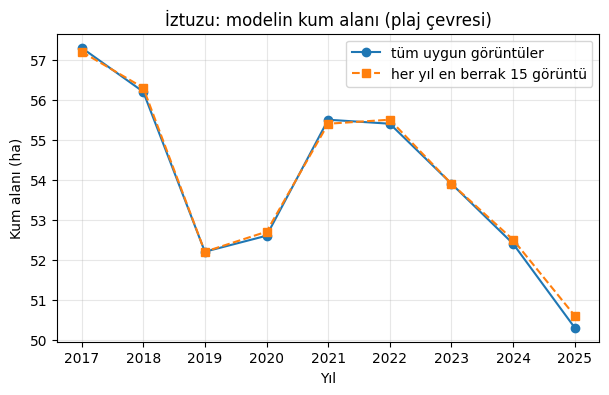

In [19]:
import matplotlib.pyplot as plt

def yillik_alan(yil, en_fazla=None):
    kol = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
           .filterBounds(bolge)
           .filterDate(f'{yil}-06-01', f'{yil}-09-01')
           .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10)))
    if en_fazla:
        kol = kol.sort('CLOUDY_PIXEL_PERCENTAGE').limit(en_fazla)
    sinif = girdi_yap(kol).classify(rf_ee)
    kum = sinif.eq(1).And(plaj_alani)
    a = kum.multiply(ee.Image.pixelArea()).reduceRegion(
        ee.Reducer.sum(), yakin, 10, maxPixels=1e9).getInfo()
    return round(list(a.values())[0] / 10000, 1)

tablo['kum_ha_15goruntu'] = [yillik_alan(y, 15) for y in tablo.yil]
print(tablo.to_string(index=False))

plt.figure(figsize=(7, 4))
plt.plot(tablo.yil, tablo.kum_ha, 'o-', label='tüm uygun görüntüler')
plt.plot(tablo.yil, tablo.kum_ha_15goruntu, 's--', label='her yıl en berrak 15 görüntü')
plt.xlabel('Yıl'); plt.ylabel('Kum alanı (ha)')
plt.title('İztuzu: modelin kum alanı (plaj çevresi)')
plt.legend(); plt.grid(alpha=.3);
plt.savefig('kum_alani_goruntu_sayisi_kontrolu.png', dpi=150, bbox_inches='tight')
plt.show()

   egitim      test  MNDWI_esik  NDVI_esik  dogruluk  f1_kum
kuzeybati guneydogu       -0.15       0.20     0.941   0.932
guneydogu kuzeybati       -0.15       0.05     0.893   0.819
Zaman serisi için eşikler: -0.15 0.2
 yil  kum_ha  kum_ha_kural
2017    57.3          70.0
2018    56.2          66.3
2019    52.2          65.4
2020    52.6          62.6
2021    55.5          72.2
2022    55.4          69.2
2023    53.9          70.3
2024    52.4          73.7
2025    50.3          66.8


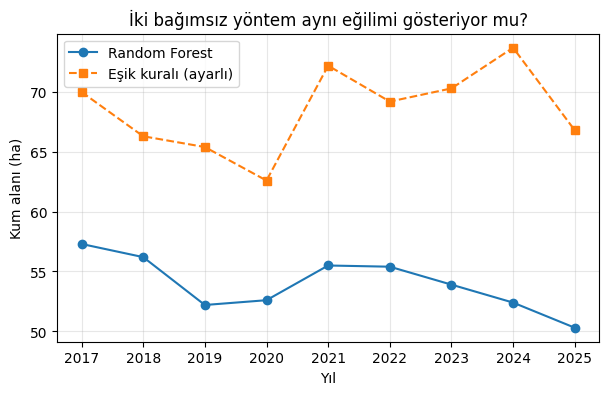

In [20]:
from itertools import product

def kural_t(d, t1, t2):
    return np.where(d.MNDWI > t1, 0, np.where(d.NDVI > t2, 2, 1))

t1s = np.arange(-0.3, 0.31, 0.05)
t2s = np.arange(0.0, 0.61, 0.05)

# 1) Adil karşılaştırma: eşikler eğitim yarısında ayarlanır, test yarısında ölçülür
sonuc2 = []
for egitim, test in [('kuzeybati', 'guneydogu'), ('guneydogu', 'kuzeybati')]:
    tr, te = df[df.bolge == egitim], df[df.bolge == test]
    t1, t2 = max(product(t1s, t2s), key=lambda t: (kural_t(tr, *t) == tr.sinif).mean())
    tah = kural_t(te, t1, t2)
    sonuc2.append(dict(egitim=egitim, test=test, MNDWI_esik=round(t1, 2), NDVI_esik=round(t2, 2),
                       dogruluk=round(float(np.mean(te.sinif == tah)), 3),
                       f1_kum=round(f1_score(te.sinif, tah, average=None, labels=[0, 1, 2])[1], 3)))
print(pd.DataFrame(sonuc2).to_string(index=False))

# 2) Zaman serisi için eşikler tüm noktalarla ayarlanır
T1, T2 = max(product(t1s, t2s), key=lambda t: (kural_t(df, *t) == df.sinif).mean())
print("Zaman serisi için eşikler:", round(T1, 2), round(T2, 2))

def alan_kural(yil):
    kol = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
           .filterBounds(bolge).filterDate(f'{yil}-06-01', f'{yil}-09-01')
           .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10)))
    g = girdi_yap(kol)
    kum = g.select('MNDWI').lte(float(T1)).And(g.select('NDVI').lte(float(T2))).And(plaj_alani)
    a = kum.multiply(ee.Image.pixelArea()).reduceRegion(
        ee.Reducer.sum(), yakin, 10, maxPixels=1e9).getInfo()
    return round(list(a.values())[0] / 10000, 1)

tablo['kum_ha_kural'] = [alan_kural(y) for y in tablo.yil]
print(tablo[['yil', 'kum_ha', 'kum_ha_kural']].to_string(index=False))

plt.figure(figsize=(7, 4))
plt.plot(tablo.yil, tablo.kum_ha, 'o-', label='Random Forest')
plt.plot(tablo.yil, tablo.kum_ha_kural, 's--', label='Eşik kuralı (ayarlı)')
plt.xlabel('Yıl'); plt.ylabel('Kum alanı (ha)')
plt.title('İki bağımsız yöntem aynı eğilimi gösteriyor mu?')
plt.legend(); plt.grid(alpha=.3);
plt.savefig('kum_alani_iki_yontem.png', dpi=150, bbox_inches='tight')
plt.show()